In [60]:
!pip install matplotlib
import math
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

11684.16s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


Defaulting to user installation because normal site-packages is not writeable


# Interpolation - Lagrange

In [61]:


def InterpolationLagrangeSimbolic( x_pts : np.array , y_pts : np.array ):
    x = sp.Symbol('x')
    polynomial = sp.S.Zero
    product = sp.S.Zero
    size : int = len( x_pts ) 
    for i in range( 0 , size ):
        product = y_pts[i]
        for j in range( 0 , size ):
            if j != i :
                product *= ( x - x_pts[j] ) / ( x_pts[i] - x_pts[j] )
        polynomial += product
    return sp.simplify(polynomial) ,  sp.lambdify( x , polynomial , 'numpy')

def InterpolationLagrange( x_pts : np.array , y_pts : np.array, point : float ):
    summ : float = 0
    product : float = 0
    size : int = len( x_pts ) 
    for i in range( 0 , size ):
        product = y_pts[i]
        for j in range( 0 , size ):
            if j != i :
                product *= ( point - x_pts[j] ) / ( x_pts[i] - x_pts[j] )
        summ += product
    return summ


X = [1, 2, 4]
Y = [2, 3, 11]

polynomial, f = InterpolationLagrangeSimbolic( X , Y )
point5 = InterpolationLagrange( X , Y , 5 )


print( f"Polymial: {polynomial}" )

print( f"Point in 5: {point5}" )

print( f"Point in 5 using polynomial: {f(5)}" )



Polymial: x**2 - 2*x + 3
Point in 5: 18.0
Point in 5 using polynomial: 18.0


# Interpolation - Newton

In [62]:
def InterpolationNewtonSimbolicGenerate( x_pts , y_pts ):
    x = sp.Symbol('x')
    size = len(x_pts)
    fdd : np.array = np.zeros( (size,size), dtype=float )
    
    for i in range( 0 , size ):
        fdd[i][0] = y_pts[i]

    for j in range( 1 , size ):
        for i in range( 0 , size - j ):
            fdd[i][j] = ( fdd[i+1][j-1] - fdd[i][j-1] ) / ( x_pts[i+j] - x_pts[i] )

    xTerm = 1

    polynomial = fdd[0][0]
    for order in range( 1 , size ):
        xTerm *= ( x - x_pts[order-1] )
        polynomial += ( fdd[0][order] * xTerm )
        
    return  sp.simplify(polynomial) ,  sp.lambdify( x , polynomial , 'numpy') , fdd 


def InterpolationNewtonSimbolicAdd( x_pts , y_pts , fdd ): # the point to be added must be only one and be at the end of the array
    x = sp.Symbol('x')
    size = len(x_pts)
    fdd_new = np.array( fdd, dtype=float )
    fdd_new = np.pad(fdd, ((0, 1), (0, 1)), mode='constant', constant_values=0)

    fdd_new[size-1][0] = y_pts[size-1]

    for j in range(1, size):
        i = size - 1 - j
        fdd_new[i][j] = (fdd_new[i + 1][j - 1] - fdd_new[i][j - 1]) / ( x_pts[i + j] - x_pts[i] )

    xTerm = 1

    polynomial = fdd_new[0][0]
    for order in range( 1 , size ):
        xTerm *= ( x - x_pts[order-1] )
        polynomial += ( fdd_new[0][order] * xTerm )

    return sp.simplify(polynomial) ,  sp.lambdify( x , polynomial , 'numpy') , fdd_new


x = [1, 2, 4]
y = [2, 3, 11]

equation , function , fdd  = InterpolationNewtonSimbolicGenerate( x , y )


print( f"Equation: {equation}" )
print( f"Point 6: {function(6)}" )
print( f"fdd: {fdd}" )

x_new = [1, 2, 4 , 6]
y_new = [2, 3, 11 , -2]

equation2 , function2 , fdd2  = InterpolationNewtonSimbolicAdd( x_new , y_new , fdd )


print( f"\nEquation: {equation2}" )
print( f"Point 6: {function2(6)}" )
print( f"fdd: {fdd2}" )



Equation: 1.0*x**2 - 2.0*x + 3.0
Point 6: 27.0
fdd: [[ 2.  1.  1.]
 [ 3.  4.  0.]
 [11.  0.  0.]]

Equation: -0.725*x**3 + 6.075*x**2 - 12.15*x + 8.8
Point 6: -2.0
fdd: [[ 2.     1.     1.    -0.725]
 [ 3.     4.    -2.625  0.   ]
 [11.    -6.5    0.     0.   ]
 [-2.     0.     0.     0.   ]]


# Linear Regression

Linear model: 8.73272727272727*x - 81.8

Linear prediction: 180.18181818181813


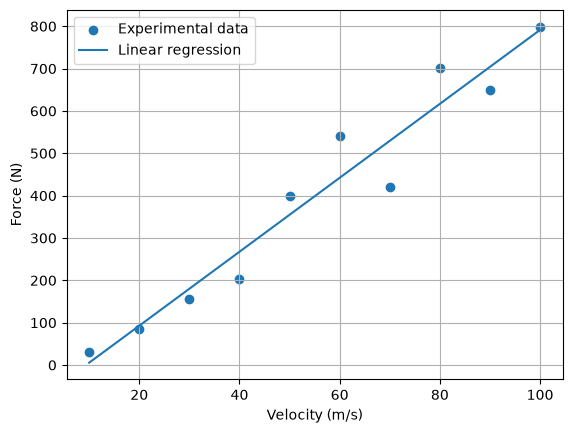

In [63]:
def LinearRegression(x, y):

    x_mean = np.mean(x)
    y_mean = np.mean(y)

    denominator = np.sum((x - x_mean) ** 2)

    if denominator == 0:
        raise ValueError("Cannot fit a line when all x values are equal")

    a1 = np.sum((x - x_mean) * (y - y_mean)) / denominator
    a0 = y_mean - a1 * x_mean

    X = sp.Symbol('x', real=True)
    simbolic = sp.Float(a0) + sp.Float(a1) * X

    f = sp.lambdify(X, simbolic, modules="numpy")

    return simbolic, f

v = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100], dtype=float)
F = np.array([30, 84, 155, 204, 400, 540, 421, 702, 650, 799], dtype=float)

f_linear_sym, f_linear = LinearRegression(v, F)

print(f"Linear model: {f_linear_sym}")


print("\nLinear prediction:", f_linear(30))

v_plot = np.linspace(v.min(), v.max(), 300)

plt.scatter(v, F, label="Experimental data")
plt.plot(v_plot, f_linear(v_plot), label="Linear regression")


plt.xlabel("Velocity (m/s)")
plt.ylabel("Force (N)")
plt.legend()
plt.grid(True)
plt.show()

# Power Regression

Power model: 1.1359181761878*x**1.44135063800283

Power prediction: 152.89620702592322


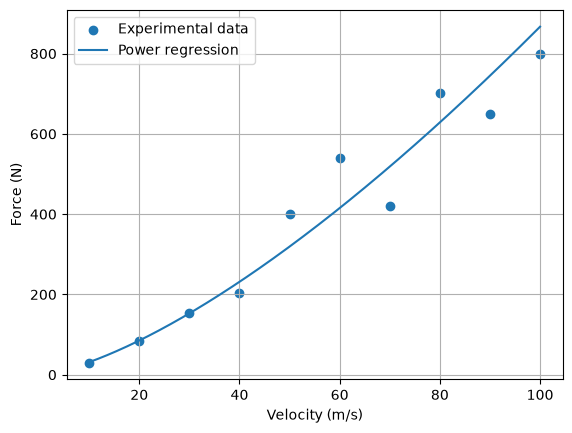

In [64]:

def PowerRegression(x, y):
    if np.any(x <= 0) or np.any(y <= 0):
        raise ValueError("Power regression requires positive x and y")

    log_x = np.log(x)
    log_y = np.log(y)

    A, f_log_lambda = LinearRegression(log_x, log_y)

    log_X = sp.Symbol('x', real=True)
    A0 = float(A.subs(log_X, 0))
    beta = float(A.coeff(log_X))

    alpha = np.exp(A0)

    X = sp.Symbol('x', positive=True)
    f_sym = sp.Float(alpha) * X ** sp.Float(beta)

    f_lambda = sp.lambdify(X, f_sym, modules="numpy")

    return f_sym, f_lambda


v = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100], dtype=float)
F = np.array([30, 84, 155, 204, 400, 540, 421, 702, 650, 799], dtype=float)

f_Power_sym, f_Power = PowerRegression(v, F)

print(f"Power model: {f_Power_sym}")


print("\nPower prediction:", f_Power(30))

v_plot = np.linspace(v.min(), v.max(), 300)

plt.scatter(v, F, label="Experimental data")
plt.plot(v_plot, f_Power(v_plot), label="Power regression")


plt.xlabel("Velocity (m/s)")
plt.ylabel("Force (N)")
plt.legend()
plt.grid(True)
plt.show()

# Relatório 3 – Interpolação e Ajuste de Função

## 1) Sensor resistivo
 
Durante a calibração de um sensor resistivo utilizado para monitorar a temperatura de um processo industrial, foram obtidos os seguintes valores:
 
| Temperatura $T$ (°C) | 0 | 20 | 40 | 60 | 80 |
|---|---|---|---|---|---|
| Resistência $R$ (Ω) | 100,00 | 107,79 | 115,54 | 123,24 | 130,90 |
 
Deseja-se construir uma função que permita estimar a resistência em temperaturas nas quais não foram realizadas medições.

In [65]:
x_1 = np.array([0 , 20 , 40 , 60 , 80] , dtype=float)
y_1 = np.array([100.00 , 107.79 , 115.54 , 123.24 , 130.90] , dtype=float)


 
### a) Determine o polinômio interpolador $P_n(T)$ utilizando os cinco pontos experimentais através da fórmula de Lagrange.


#### Answer

The interpolating polynomial is:
 
$$
P_4(T) \approx 5{,}208\times10^{-9}\,T^4 - 8{,}333\times10^{-7}\,T^3 - 1{,}458\times10^{-5}\,T^2 + 0{,}39008\,T + 100{,}00
$$

For precise numerical accuracy see the output of the python script.

In [81]:
simbolic_1, function_1 = InterpolationLagrangeSimbolic( x_1 , y_1 ) 

print( f"Polynomial: {simbolic_1}" )

Polynomial: 5.20833333337016e-9*x**4 - 8.33333333338793e-7*x**3 - 1.45833333331513e-5*x**2 + 0.390083333333333*x + 100.0


 
### b) Utilize a função para estimar a resistência nas temperaturas $T = 35\,°C$ e $T = 65\,°C$.
 


#### **Answer**
 
Evaluating $P_4(T)$ at the requested temperatures:
 
$$
R(35\,°\text{C}) = P_4(35) \approx \mathbf{113{,}607\ \Omega}
$$
 
$$
R(65\,°\text{C}) = P_4(65) \approx \mathbf{125{,}158\ \Omega}
$$
 
Both values lie inside the calibrated range ($0 \le T \le 80$ °C), so they are interpolations, not extrapolations.

For precise numerical accuracy see the output of the python script.

In [67]:
print(f"T = 35°C: {function_1(35)} Ω\n")
print(f"T = 65°C: {function_1(65)} Ω\n")

T = 35°C: 113.60713867187485 Ω

T = 65°C: 125.15791992187468 Ω



### c) Construa o gráfico da curva interpoladora para $0 \le T \le 80\,°C$. Identifique no gráfico os dois pontos estimados.

#### Answer

The curve starts at $100{,}00\ \Omega$ and grows smoothly to $130{,}90\ \Omega$, passing exactly through the five experimental points. The two estimated points (red) lie on the curve(not exactly) between the measured points, at $T = 35$ °C and $T = 65$ °C.

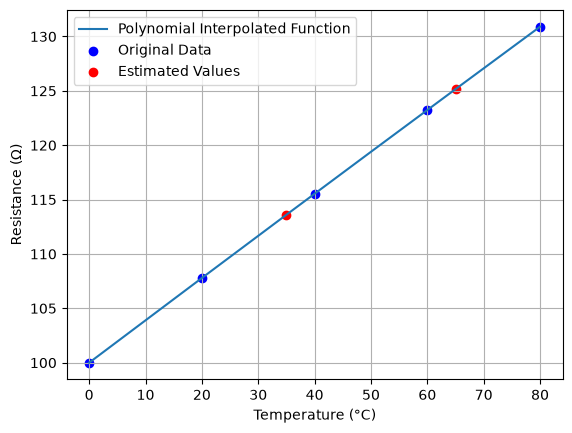

In [68]:
v_plot = np.linspace(0, 80, 300)

plt.plot(v_plot, function_1(v_plot), label="Polynomial Interpolated Function")
plt.scatter(x_1, y_1, label="Original Data", color='blue')
x_temp = [35, 65]
y_temp = []
y_temp.append(function_1(35))
y_temp.append(function_1(65))
plt.scatter(x_temp, y_temp, label="Estimated Values", color='red')


plt.xlabel("Temperature (°C)")
plt.ylabel("Resistance (Ω)")
plt.legend()
plt.grid(True)
plt.show()

## 2) Bomba centrífuga
 
Durante o ensaio de uma bomba centrífuga, a eficiência global foi medida para diferentes vazões:
 
| Vazão $Q$ (m³/h) | 10 | 18 | 27 | 39 | 52 |
|---|---|---|---|---|---|
| Eficiência $\eta$ (%) | 58 | 68 | 76 | 80 | 77 |
 
Deseja-se construir uma função que permita estimar a eficiência em condições intermediárias de operação.

In [69]:
x_2 = np.array([10 , 18 , 27 , 39 , 52] , dtype=float)
y_2 = np.array([58 , 68 , 76 , 80 , 77] , dtype=float)


### a) Implemente o método de diferenças divididas de Newton.

#### Answer

Divided-difference table ($Q$ in m³/h, $\eta$ in %):
 
| $Q_i$ | $\eta_i$ | 1st order | 2nd order | 3rd order | 4th order |
|:---:|:---:|:---:|:---:|:---:|:---:|
| 10 | 58 | 1,25000 | −0,021242 | −1,7977×10⁻⁴ | 7,0049×10⁻⁶ |
| 18 | 68 | 0,88889 | −0,026455 | 1,1444×10⁻⁴ | |
| 27 | 76 | 0,33333 | −0,022564 | | |
| 39 | 80 | −0,23077 | | | |
| 52 | 77 | | | | |
 
The coefficients are the first row of the table, so:
 
$$
P_4(Q) \approx 7{,}0049\times10^{-6}\,Q^4 - 8{,}3822\times10^{-4}\,Q^3 + 0{,}010227\,Q^2 + 1{,}38676\,Q + 43{,}878
$$

For precise numerical accuracy see the output of the python script.

In [70]:
simbolic_2, function_2, fdd_2 = InterpolationNewtonSimbolicGenerate( x_2 , y_2 )

print( f"Polynomial: {simbolic_2}\n" )

print( f"Fdd: {fdd_2}\n" )

Polynomial: 7.0048650170354e-6*x**4 - 0.000838222704348465*x**3 + 0.0102272556532191*x**2 + 1.38676159765409*x + 43.8778325123153

Fdd: [[ 5.80000000e+01  1.25000000e+00 -2.12418301e-02 -1.79765393e-04
   7.00486502e-06]
 [ 6.80000000e+01  8.88888889e-01 -2.64550265e-02  1.14438938e-04
   0.00000000e+00]
 [ 7.60000000e+01  3.33333333e-01 -2.25641026e-02  0.00000000e+00
   0.00000000e+00]
 [ 8.00000000e+01 -2.30769231e-01  0.00000000e+00  0.00000000e+00
   0.00000000e+00]
 [ 7.70000000e+01  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00]]



### b) Utilize a função para estimar a vazão quando a eficiência for $\eta(32)$ e $\eta(45)$.

#### Answer
 
The notation $\eta(32)$ and $\eta(45)$ means the efficiency at flow rates $Q = 32$ and $Q = 45$ m³/h:
 
$$
\eta(32) = P_4(32) \approx \mathbf{78{,}61\ \%}
$$
 
$$
\eta(45) = P_4(45) \approx \mathbf{79{,}33\ \%}
$$

For precise numerical accuracy see the output of the python script.

In [71]:
print(f"η(Q=32 m³/h): {function_2(32)}%\n")
print(f"η(Q=45 m³/h): {function_2(45)}%\n")

η(Q=32 m³/h): 78.60516519015505%

η(Q=45 m³/h): 79.33357778124511%



### c) Construa o gráfico da curva interpoladora para $10 \le Q \le 52$ m³/h. Identifique no gráfico os dois pontos estimados.
 

#### Answer
 
The curve passes through all five measured points. Efficiency rises quickly at low flow, reaches a maximum of about $80\ \%$ near $Q \approx 40$ m³/h, and then decreases slightly up to $Q = 52$ m³/h. The two estimated points (red), $Q = 32$ and $Q = 45$ m³/h, lie on the curve(not exactly) close to this maximum.

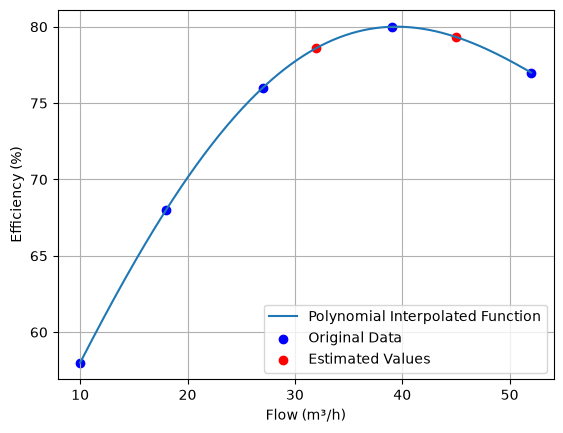

In [72]:
v_plot = np.linspace(10, 52, 300)

plt.plot(v_plot, function_2(v_plot), label="Polynomial Interpolated Function")
plt.scatter(x_2, y_2, label="Original Data", color='blue')
x_temp = [32, 45]
y_temp = []
y_temp.append(function_2(32))
y_temp.append(function_2(45))
plt.scatter(x_temp, y_temp, label="Estimated Values", color='red')


plt.xlabel("Flow (m³/h)")
plt.ylabel("Efficiency (%)")
plt.legend()
plt.grid(True)
plt.show()

### d) Acrescente $Q = 60$ m³/h e $\eta = 72\%$ à tabela de diferenças divididas e determine o novo termo necessário para construir $P_5(Q)$. Explique por que a forma de Newton é conveniente quando novos dados são acrescentados sequencialmente.

#### Answer
 
Adding the point $(Q_5, \eta_5) = (60,\ 72)$ only creates a new diagonal in the table, because the previous entries do not change:
 
| $Q_i$ | $\eta_i$ | 1st order | 2nd order | 3rd order | 4th order | 5th order |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| 10 | 58 | 1,25000 | −0,021242 | −1,7977×10⁻⁴ | 7,0049×10⁻⁶ | **−1,3988×10⁻⁷** |
| 18 | 68 | 0,88889 | −0,026455 | 1,1444×10⁻⁴ | 1,0623×10⁻⁸ | |
| 27 | 76 | 0,33333 | −0,022564 | 1,1489×10⁻⁴ | | |
| 39 | 80 | −0,23077 | −0,018773 | | | |
| 52 | 77 | −0,62500 | | | | |
| 60 | 72 | | | | | |
 
The new term needed to build $P_5(Q)$ is:
 
$$
f[Q_0, Q_1, Q_2, Q_3, Q_4, Q_5] \approx -1{,}3988\times10^{-7}
$$
 
so that:
 
$$
P_5(Q) \approx -1{,}3988\times10^{-7}\,Q^5 + 2{,}7428\times10^{-5}\,Q^4 - 1{,}9530\times10^{-3}\,Q^3 + 0{,}038425\,Q^2 + 1{,}05937\,Q + 45{,}257
$$
 
**Why Newton's form is convenient:** when a new data point is added, all the previous coefficients $f[Q_0], f[Q_0,Q_1], \dots, f[Q_0,\dots,Q_4]$ and the polynomial $P_4(Q)$ are reused. Only one new diagonal of the table (one new coefficient) must be computed, and $P_5$ is obtained by adding a single term to $P_4$:

 
In Lagrange's form, in contrast, every basis polynomial $L_i$ changes when a node is added, so the whole polynomial must be recomputed.

For precise numerical accuracy see the output of the python script.

In [82]:
x_2d = np.append(x_2, 60)
y_2d = np.append(y_2, 72)

simbolic_2d, function_2d, fdd_2d = InterpolationNewtonSimbolicGenerate( x_2d , y_2d )

print( f"Polynomial: {simbolic_2d}\n" )

print( f"Fdd: {fdd_2d}\n" )


Polynomial: -1.39884835142249e-7*x**5 + 2.74280509478037e-5*x**4 - 0.00195296495559704*x**3 + 0.038424681181853*x**2 + 1.05936561731838*x + 45.2565486382641

Fdd: [[ 5.80000000e+01  1.25000000e+00 -2.12418301e-02 -1.79765393e-04
   7.00486502e-06 -1.39884835e-07]
 [ 6.80000000e+01  8.88888889e-01 -2.64550265e-02  1.14438938e-04
   1.06232599e-08  0.00000000e+00]
 [ 7.60000000e+01  3.33333333e-01 -2.25641026e-02  1.14885115e-04
   0.00000000e+00  0.00000000e+00]
 [ 8.00000000e+01 -2.30769231e-01 -1.87728938e-02  0.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 7.70000000e+01 -6.25000000e-01  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 7.20000000e+01  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00]]



## 3) Levantamento topográfico
 
Durante o levantamento topográfico preliminar de uma estrada, foram medidas as seguintes elevações:
 
| Distância $x$ (m) | 0 | 80 | 170 | 290 | 420 | 600 |
|---|---|---|---|---|---|---|
| Elevação $z$ (m) | 12,0 | 14,8 | 13,9 | 18,1 | 17,4 | 20,2 |

### a) Determine os coeficientes $a_i, b_i, c_i, d_i$ para cada intervalo.
 

### b) Determine as elevações estimadas em $x = 125$ m, $x = 230$ m, $x = 500$ m.
 

### c) Construa um gráfico do perfil topográfico completo, contendo os dados medidos e a spline.

## 4) Ensaio em túnel de vento
 
Um componente foi submetido a ensaios em túnel de vento. Para diferentes velocidades do escoamento, foram medidas as seguintes forças de arrasto:
 
| Velocidade $v$ (m/s) | 10 | 20 | 30 | 40 | 50 | 60 | 70 | 80 |
|---|---|---|---|---|---|---|---|---|
| Força $F$ (N) | 26 | 94 | 205 | 360 | 565 | 790 | 1090 | 1420 |
 
Ao contrário dos três problemas anteriores, esses dados possuem incerteza experimental. Portanto, não se deseja uma função que passe exatamente por todos os pontos, mas uma função que represente adequadamente sua tendência.

In [74]:
x_4 = np.array([10 , 20 , 30 , 40, 50 , 60 , 70 , 80] , dtype=float)
y_4 = np.array([26 , 94 , 205 , 360 , 565 , 790 , 1090 , 1420] , dtype=float)

def Metrics(y, y_pred):
    residuals = y - y_pred
    Sr = np.sum(residuals ** 2)
    St = np.sum((y - np.mean(y)) ** 2)
    rmse = np.sqrt(Sr / len(y))
    r2 = 1 - Sr / St
    return Sr, rmse, r2, residuals


### a) Considere $F(v) = a_0 + a_1 v$ (modelo linear). Determine $a_0$ e $a_1$. Calcule $S_r$, $RMSE$ e $R^2$.

#### Answer

For the linear model $F(v) = a_0 + a_1 v$, least squares gives:
 
$$
\boxed{F(v) \approx -325{,}79 + 19{,}879\,v}
$$
$$
\boxed{a_0 \approx -325{,}79}
$$
$$
\boxed{a_1 \approx 19{,}879}
$$
 
Error metrics:
 
$$
S_r  \approx 81\,487{,}57\ \text{N}^2
$$
 
$$
RMSE  \approx 100{,}93\ \text{N}
$$
 
$$
R^2 \approx 0{,}9532
$$

For precise numerical accuracy see the output of the python script.

In [75]:
simbolic4a , function_4a = LinearRegression( x_4 , y_4 )

print( f"Simbolic: {simbolic4a}\n" )

Sr_l, rmse_l, r2_l, residuals_l = Metrics( y_4 , function_4a(x_4) )

print(f"Metrics: Sr={Sr_l:.2f}  RMSE={rmse_l:.2f}  R²={r2_l:.4f}")

Simbolic: 19.8785714285714*x - 325.785714285714

Metrics: Sr=81487.57  RMSE=100.93  R²=0.9532


### b) Considere $F(v) = \alpha v^{\beta}$ (modelo de potência). Determinar $\alpha$ e $\beta$. Calcule $S_r$, $RMSE$ e $R^2$.

#### Answer

A linear least-squares fit of $\ln F$ against $\ln v$ gives $\beta$ as the slope and $\alpha = e^{\text{intercept}}$:
 
$$
\boxed{F(v) \approx 0{,}2980\, v^{1{,}9278}}
$$
 
$$
\boxed{\beta \approx 1{,}9278}
$$

$$
\boxed{\alpha \approx 0{,}2980}
$$


Error metrics:
 
$$
S_r \approx 1\,252{,}06\ \text{N}^2
$$
$$
RMSE \approx 12{,}51\ \text{N}
$$
$$
R^2 \approx 0{,}9993
$$


For precise numerical accuracy see the output of the python script.

In [76]:
simbolic4b , function_4b = PowerRegression( x_4 , y_4 )

print( f"Simbolic: {simbolic4b}\n" )

Sr_p, rmse_p, r2_p, residuals_p = Metrics( y_4 , function_4b(x_4) )

print(f"Metrics: Sr={Sr_p:.2f}  RMSE={rmse_p:.2f}  R²={r2_p:.4f}")

Simbolic: 0.298045315571386*x**1.9278291203389

Metrics: Sr=1252.06  RMSE=12.51  R²=0.9993


### c) Construa três gráficos:
   



#### **Answer**
 
**Graph 1 – data and models:** the power model follows the experimental points closely along the whole range. The linear model is a straight line, but the data curve upward. Because of this, the line stays below the points at the beginning and at the end ($v = 10$ and $v = 80$ m/s) and above the points in the middle. At $v = 10$ m/s the line even gives a negative force ($\approx -127$ N).
 
**Graph 2 – residuals of the linear model:** the residuals form a clear **U shape**, from $+153$ N at $v = 10$ m/s, down to about $-109$ N at $v = 40$ m/s, and back up to $+155{,}5$ N at $v = 80$ m/s. This systematic pattern shows that the linear model is **not adequate**, even with $R^2 = 0{,}95$.
 
**Graph 3 – residuals of the power model:** the residuals are much smaller (between $-8{,}5$ and $+29{,}7$ N, at most about $2\ \%$ of $F$) and show no clear curved pattern. The largest values appear at high velocities, where $F$ itself is larger.
 
**Comparison:**
 
| Model | $S_r$ (N²) | $RMSE$ (N) | $R^2$ |
|:---|:---:|:---:|:---:|
| Linear | 81 487,57 | 100,93 | 0,9532 |
| Power | 1 252,06 | 12,51 | 0,9993 |
 
The power model reduces $S_r$ by about $65$ times and has a much smaller $RMSE$, so it is the better representation of the trend of the data.

1. dados experimentais juntamente com os modelos linear e de potência;

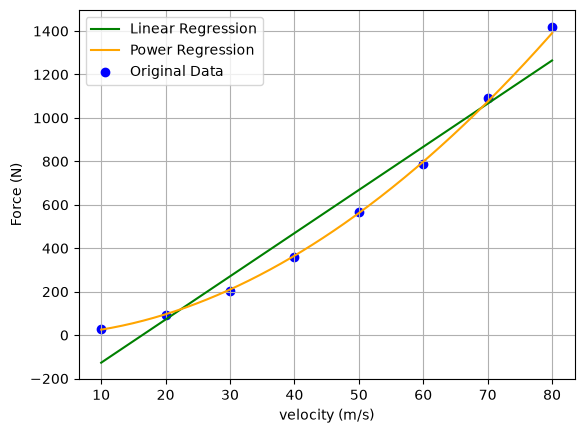

In [77]:
v_plot = np.linspace(10, 80, 300)

plt.plot(v_plot, function_4a(v_plot), label="Linear Regression", color="green")
plt.plot(v_plot, function_4b(v_plot), label="Power Regression", color="orange")
plt.scatter(x_4, y_4, label="Original Data", color='blue')

plt.xlabel("velocity (m/s)")
plt.ylabel("Force (N)")
plt.legend()
plt.grid(True)
plt.show()

   2. resíduos do modelo linear em função de $v$;

[ 153.           22.21428571  -65.57142857 -109.35714286 -103.14285714
  -76.92857143   24.28571429  155.5       ]


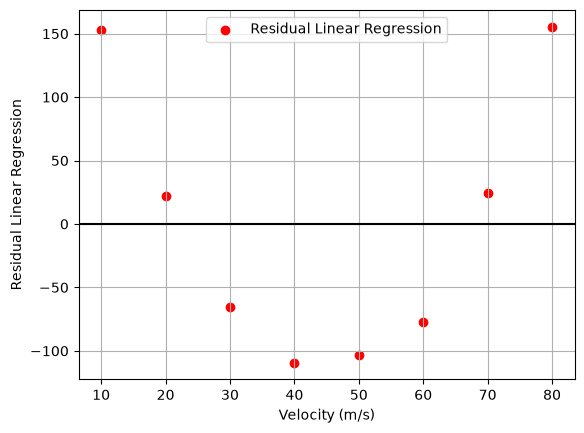

In [78]:
print(residuals_l)

v_plot = np.linspace(10, 80, 300)

plt.axhline(0, color='k')
plt.scatter(x_4, residuals_l, label="Residual Linear Regression", color='red')

plt.xlabel("Velocity (m/s)")
plt.ylabel("Residual Linear Regression")
plt.legend()
plt.grid(True)
plt.show()


   3. resíduos do modelo de potência em função de $v$.

[ 0.75871731 -2.03859821 -4.8551683  -5.4098114   3.16841681 -8.46164876
 15.22877186 29.68055806]


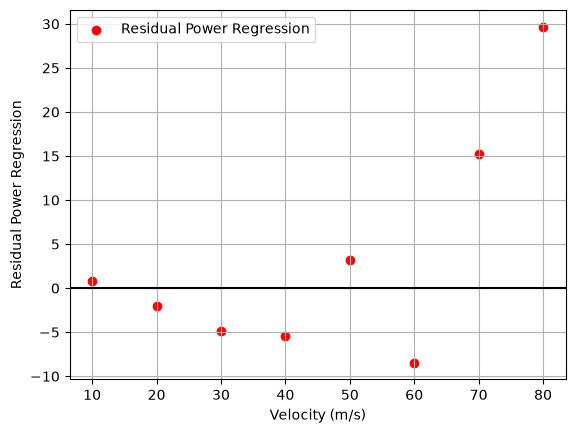

In [79]:
print(residuals_p)

v_plot = np.linspace(10, 80, 300)

plt.axhline(0, color='k')
plt.scatter(x_4, residuals_p, label="Residual Power Regression", color='red')

plt.xlabel("Velocity (m/s)")
plt.ylabel("Residual Power Regression")
plt.legend()
plt.grid(True)
plt.show()
